In [1]:
import numpy as np
from sklearn.datasets import load_iris 
from sklearn.linear_model import Perceptron 

iris = load_iris(as_frame=True)
X = iris.data[["petal length (cm)", "petal width (cm)"]].values
y = (iris.target == 0)

per_clf = Perceptron(random_state=42)
per_clf.fit(X, y)

X_new = [[2, 0.5], [3, 1]]
y_pred = per_clf.predict(X_new)

In [2]:
y_pred

array([ True, False])

In [3]:
y

0       True
1       True
2       True
3       True
4       True
       ...  
145    False
146    False
147    False
148    False
149    False
Name: target, Length: 150, dtype: bool

In [4]:
from sklearn.datasets import fetch_california_housing
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

housing = fetch_california_housing()

X_train_full, X_test, y_train_full, y_test = train_test_split(
    housing.data, housing.target, random_state=42
)
X_train, X_valid, y_train, y_valid = train_test_split(
    X_train_full, y_train_full, random_state=42
)

mlp_reg = MLPRegressor(hidden_layer_sizes=[50, 50, 50], random_state=42)
pipeline = make_pipeline(StandardScaler(), mlp_reg)
pipeline.fit(X_train, y_train)
y_pred = pipeline.predict(X_valid)
rmse = root_mean_squared_error(y_valid, y_pred)




In [5]:
rmse

0.5053326657968684

In [6]:
from sklearn.dummy import DummyRegressor
from sklearn.pipeline import make_pipeline
from sklearn.metrics import root_mean_squared_error

dummy = make_pipeline(
    StandardScaler(),
    DummyRegressor(strategy="mean")
)

dummy.fit(X_train, y_train)

dummy_pred = dummy.predict(X_valid)

dummy_rmse = root_mean_squared_error(y_valid, dummy_pred)

print("Baseline rmse : ", dummy_rmse)
print("Neural Network rmse : ", rmse)

Baseline rmse :  1.1476260241965577
Neural Network rmse :  0.5053326657968684


In [7]:
from sklearn.ensemble import RandomForestRegressor

rfr = make_pipeline(
    StandardScaler(),
    RandomForestRegressor(random_state=42)
)

rfr.fit(X_train, y_train)

rfr_pred = rfr.predict(X_valid)

rfr_rmse = root_mean_squared_error(y_valid, rfr_pred)

print("Random Forest rmse: ", rfr_rmse)

Random Forest rmse:  0.5073847566107056


In [8]:
from sklearn.neural_network import MLPClassifier

iris = load_iris()

X_train_full, X_test, y_train_full, y_test = train_test_split(
    iris.data, iris.target, random_state=42
)

X_train, X_valid, y_train, y_valid = train_test_split(
    X_train_full, y_train_full, random_state=42
)

mlpc = MLPClassifier(hidden_layer_sizes=[5])

pipeline = make_pipeline(StandardScaler(),
                         mlpc
)

pipeline.fit(X_train, y_train)

mlpc_pred = pipeline.predict(X_valid)

mlpc_rmse  = root_mean_squared_error(y_valid, mlpc_pred)
print("MLPClassifier rmse : ", mlpc_rmse)

MLPClassifier rmse :  0.8451542547285166


/home/chintu/miniconda3/envs/ml-ops/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


In [9]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_valid, mlpc_pred)

print("MLPClassifier Accuracy:", accuracy)

MLPClassifier Accuracy: 0.5


In [10]:
from sklearn.neural_network import MLPClassifier

iris = load_iris()

X_train_full, X_test, y_train_full, y_test = train_test_split(
    iris.data, iris.target, random_state=42
)

X_train, X_valid, y_train, y_valid = train_test_split(
    X_train_full, y_train_full, random_state=42
)

mlpc = MLPClassifier(hidden_layer_sizes=[10])

pipeline = make_pipeline(StandardScaler(),
                         mlpc
)

pipeline.fit(X_train, y_train)

mlpc_pred = pipeline.predict(X_valid)

mlpc_rmse  = root_mean_squared_error(y_valid, mlpc_pred)
print("MLPClassifier rmse : ", mlpc_rmse)

MLPClassifier rmse :  0.3779644730092272


/home/chintu/miniconda3/envs/ml-ops/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


In [11]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_valid, mlpc_pred)

print("MLPClassifier Accuracy:", accuracy)

MLPClassifier Accuracy: 0.8571428571428571


In [12]:
import tensorflow as tf 

fashion_mnist = tf.keras.datasets.fashion_mnist.load_data()
(X_train_full, y_train_full), (X_test, y_test) = fashion_mnist 
X_train, y_train = X_train_full[:-5000], y_train_full[:-5000]
X_valid, y_valid = X_train_full[-5000:], y_train_full[-5000:]

I0000 00:00:1794458172.620292   28405 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [13]:
print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_valid.shape, y_valid.shape)
print("Testing:", X_test.shape, y_test.shape)

Training: (55000, 28, 28) (55000,)
Validation: (5000, 28, 28) (5000,)
Testing: (10000, 28, 28) (10000,)


In [14]:
X_train, X_valid, X_test = (
    X_train / 255. ,
    X_valid / 255. ,
    X_test / 255. 
)

In [15]:
print(X_train.min())
print(X_train.max())
print(X_train.dtype)

0.0
1.0
float64


In [16]:
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker","Bag", "Ankle boot"]

In [17]:
class_names[y_train[8]]

'Sandal'

In [18]:
class_names[y_train[4]]

'T-shirt/top'

In [19]:
tf.random.set_seed(42)

model = tf.keras.Sequential()

model.add(tf.keras.layers.Input(shape=[28, 28]))

model.add(tf.keras.layers.Flatten())

model.add(tf.keras.layers.Dense(300,activation="relu"))

model.add(tf.keras.layers.Dense(100,activation="relu"))

model.add(tf.keras.layers.Dense(10,activation="softmax"))
 

W0000 00:00:1794458177.649202   28405 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


In [20]:
model = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=[28, 28]),
    tf.keras.layers.Dense(300, activation="relu"),
    tf.keras.layers.Dense(100, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

/home/chintu/miniconda3/envs/ml-ops/lib/python3.11/site-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [21]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 300)            │       235,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 100)            │        30,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 266,610 (1.02 MB)

 Trainable params: 266,610 (1.02 MB)

 Non-trainable params: 0 (0.00 B)

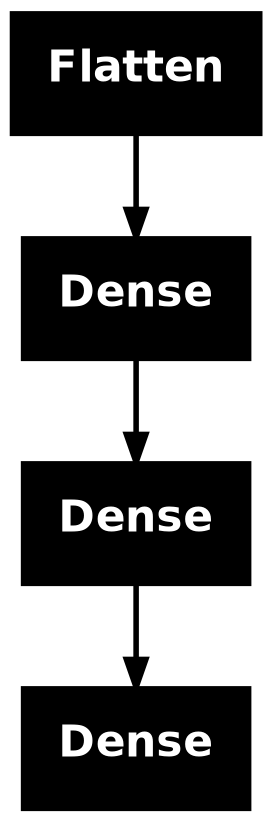

In [22]:
tf.keras.utils.plot_model(model)

In [23]:
model.layers

[<Flatten name=flatten_1, built=True>,
 <Dense name=dense_3, built=True>,
 <Dense name=dense_4, built=True>,
 <Dense name=dense_5, built=True>]

In [24]:
hidden1 = model.layers[1]

In [25]:
hidden1

<Dense name=dense_3, built=True>

In [26]:
model.get_layer('dense_3') is hidden1

True

In [27]:
weights, biases = hidden1.get_weights()

In [28]:
weights

array([[ 0.06676698,  0.00299332, -0.07093992, ...,  0.03397599,
         0.02386197,  0.02899268],
       [ 0.0683402 ,  0.0650588 , -0.05849132, ..., -0.01643485,
        -0.02411867,  0.0628929 ],
       [-0.07394454,  0.04677944,  0.05691282, ..., -0.0299225 ,
        -0.06667776, -0.05719358],
       ...,
       [ 0.06291518,  0.04038728, -0.03843867, ..., -0.06310004,
         0.05016744,  0.02990483],
       [-0.01494155, -0.01459758, -0.00630958, ...,  0.07041633,
         0.06860617,  0.06250466],
       [-0.01386265, -0.0371829 ,  0.02353283, ..., -0.00708489,
        -0.02030108, -0.07208747]], shape=(784, 300), dtype=float32)

In [29]:
weights.shape


(784, 300)

In [30]:
biases

array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0.

In [31]:
biases.shape

(300,)

In [32]:
model.compile(loss="sparse_categorical_crossentropy",
              optimizer="sgd",
              metrics=["accuracy"])

In [33]:
history = model.fit(X_train, y_train, epochs=30,
                    validation_data=(X_valid, y_valid))

Epoch 1/30


W0000 00:00:1794458179.282312   28405 cpu_allocator_impl.cc:82] Allocation of 172480000 exceeds 10% of free system memory.


1719/1719 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7715 - loss: 0.7086

W0000 00:00:1794458182.267010   28405 cpu_allocator_impl.cc:82] Allocation of 15680000 exceeds 10% of free system memory.


1719/1719 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.7715 - loss: 0.7086 - val_accuracy: 0.8300 - val_loss: 0.5074
Epoch 2/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8332 - loss: 0.4855 - val_accuracy: 0.8416 - val_loss: 0.4552
Epoch 3/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8479 - loss: 0.4399 - val_accuracy: 0.8500 - val_loss: 0.4313
Epoch 4/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8570 - loss: 0.4125 - val_accuracy: 0.8530 - val_loss: 0.4136
Epoch 5/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8630 - loss: 0.3923 - val_accuracy: 0.8550 - val_loss: 0.4026
Epoch 6/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8675 - loss: 0.3761 - val_accuracy: 0.8568 - val_loss: 0.3931
Epoch 7/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8719 - loss: 0.3628 - val_accuracy: 0.8598 - val_loss: 0.3848
Epoch 8/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8756 - loss: 0.3512 - val_accurac

In [34]:
history.params

{'verbose': 'auto', 'epochs': 30, 'steps': 1719}

In [35]:
history.epoch

[0,
 1,
 2,
 3,
 4,
 5,
 6,
 7,
 8,
 9,
 10,
 11,
 12,
 13,
 14,
 15,
 16,
 17,
 18,
 19,
 20,
 21,
 22,
 23,
 24,
 25,
 26,
 27,
 28,
 29]

In [36]:
history.history

{'accuracy': [0.7714909315109253,
  0.8332363367080688,
  0.8478727340698242,
  0.8569999933242798,
  0.8629817962646484,
  0.8674727082252502,
  0.8719272613525391,
  0.8755818009376526,
  0.8791999816894531,
  0.8823272585868835,
  0.8852545619010925,
  0.8877090811729431,
  0.8898363709449768,
  0.8925091028213501,
  0.8939818143844604,
  0.896399974822998,
  0.8987818360328674,
  0.9008545279502869,
  0.9029091000556946,
  0.9047999978065491,
  0.9066181778907776,
  0.9083818197250366,
  0.9103817939758301,
  0.911727249622345,
  0.9133090972900391,
  0.9148363471031189,
  0.9166181683540344,
  0.918327271938324,
  0.9197999835014343,
  0.9216363430023193],
 'loss': [0.7085707187652588,
  0.4854593873023987,
  0.4398626983165741,
  0.41252264380455017,
  0.39227452874183655,
  0.3761230707168579,
  0.3627869784832001,
  0.35116177797317505,
  0.3409736752510071,
  0.3318164646625519,
  0.32326561212539673,
  0.3153648376464844,
  0.30795496702194214,
  0.3010215163230896,
  0.29461

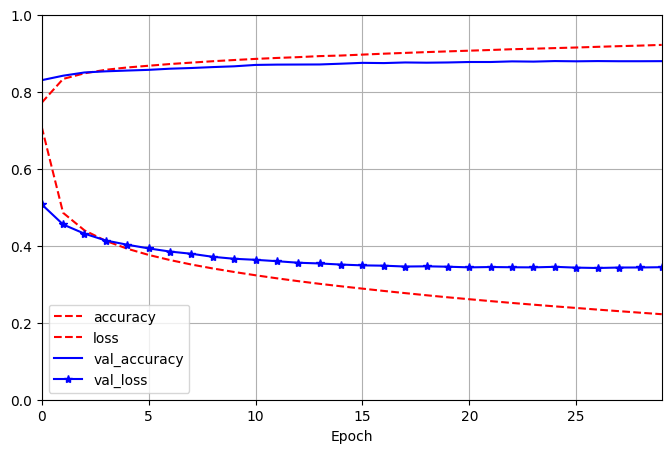

In [37]:
import matplotlib.pyplot as plt
import pandas as pd

pd.DataFrame(history.history).plot(
    figsize=(8,5), xlim=[0,29], ylim=[0, 1], xlabel="Epoch", style=["r--", "r--", "b-","b-*"])
plt.grid()
plt.show()


In [38]:
model.evaluate(X_test, y_test)

173/313 ━━━━━━━━━━━━━━━━━━━━ 0s 880us/step - accuracy: 0.8676 - loss: 0.3801

W0000 00:00:1794458249.351839   28405 cpu_allocator_impl.cc:82] Allocation of 31360000 exceeds 10% of free system memory.


313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 905us/step - accuracy: 0.8752 - loss: 0.3602


[0.36016762256622314, 0.8751999735832214]

In [39]:
X_new = X_test[:3]
y_proba = model.predict(X_new)
y_proba.round(2)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step


array([[0.  , 0.  , 0.  , 0.  , 0.  , 0.21, 0.  , 0.01, 0.  , 0.78],
       [0.  , 0.  , 1.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  ],
       [0.  , 1.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  ]],
      dtype=float32)

In [40]:
y_test[:3]

array([9, 2, 1], dtype=uint8)

In [41]:
import numpy as np
y_pred = y_proba.argmax(axis=1)
y_pred

array([9, 2, 1])

In [42]:
from sklearn.datasets import fetch_california_housing
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

housing = fetch_california_housing()

X_train_full, X_test, y_train_full, y_test = train_test_split(
    housing.data, housing.target, random_state=42
)
X_train, X_valid, y_train, y_valid = train_test_split(
    X_train_full, y_train_full, random_state=42
)

mlp_reg = MLPRegressor(hidden_layer_sizes=[50, 50, 50], random_state=42)
pipeline = make_pipeline(StandardScaler(), mlp_reg)
pipeline.fit(X_train, y_train)
y_pred = pipeline.predict(X_valid)
rmse = root_mean_squared_error(y_valid, y_pred)

In [43]:
tf.random.set_seed(42)
norm_layer = tf.keras.layers.Normalization(input_shape=X_train.shape[1:])
model = tf.keras.Sequential([
    norm_layer,
    tf.keras.layers.Dense(50, activation="relu"),
    tf.keras.layers.Dense(50, activation="relu"),
    tf.keras.layers.Dense(50, activation="relu"),
    tf.keras.layers.Dense(1)
])

optimizer = tf.keras.optimizers.Adam(learning_rate=1e-3)
model.compile(loss="mse", optimizer=optimizer, metrics=["root_mean_squared_error"])
norm_layer.adapt(X_train)
history = model.fit(X_train, y_train, epochs=20, validation_data=(X_valid, y_valid))
mse_test , rmse_test = model.evaluate(X_test, y_test)

/home/chintu/miniconda3/envs/ml-ops/lib/python3.11/site-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 1.0206 - root_mean_squared_error: 1.0102 - val_loss: 0.4500 - val_root_mean_squared_error: 0.6709
Epoch 2/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.3922 - root_mean_squared_error: 0.6262 - val_loss: 0.4004 - val_root_mean_squared_error: 0.6328
Epoch 3/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.3561 - root_mean_squared_error: 0.5967 - val_loss: 0.6970 - val_root_mean_squared_error: 0.8349
Epoch 4/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.3373 - root_mean_squared_error: 0.5808 - val_loss: 0.3211 - val_root_mean_squared_error: 0.5667
Epoch 5/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.3323 - root_mean_squared_error: 0.5765 - val_loss: 1.5714 - val_root_mean_squared_error: 1.2535
Epoch 6/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.3270 - root_mean_squared_error: 0.5718 - val_loss: 2.1002 - val_root_mean_squared_error: 1.4492
Epoch 7/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 

In [44]:
X_new = X_test[:3]
y_pred = model.predict(X_new)
y_pred

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step


array([[0.48836008],
       [1.1419725 ],
       [4.8431644 ]], dtype=float32)

In [45]:
X_new.shape

(3, 8)

In [46]:
y_test[:3]

array([0.477  , 0.458  , 5.00001])

In [47]:
normalization_layer = tf.keras.layers.Normalization()
hidden_layer1 = tf.keras.layers.Dense(30, activation="relu")
hidden_layer2 = tf.keras.layers.Dense(30, activation="relu")
concat_layer  = tf.keras.layers.Concatenate()
output_layer = tf.keras.layers.Dense(1)

input_ = tf.keras.layers.Input(shape=X_train.shape[1:])
normalized = normalization_layer(input_)
hidden1 = hidden_layer1(normalized)
hidden2 = hidden_layer2(hidden1)
concat = concat_layer([normalized, hidden2])
output = output_layer(concat)

model = tf.keras.Model(inputs=[input_], outputs=[output])
model.compile(loss="mse", optimizer="adam", metrics=["root_mean_squared_error"])
normalization_layer.adapt(X_train)
model.fit(X_train, y_train, epochs=20, validation_data=(X_valid, y_valid))


Epoch 1/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 1.0128 - root_mean_squared_error: 1.0064 - val_loss: 0.6128 - val_root_mean_squared_error: 0.7828
Epoch 2/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.4411 - root_mean_squared_error: 0.6641 - val_loss: 0.4236 - val_root_mean_squared_error: 0.6508
Epoch 3/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.3897 - root_mean_squared_error: 0.6243 - val_loss: 0.3923 - val_root_mean_squared_error: 0.6263
Epoch 4/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.3703 - root_mean_squared_error: 0.6086 - val_loss: 0.3542 - val_root_mean_squared_error: 0.5952
Epoch 5/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.3583 - root_mean_squared_error: 0.5986 - val_loss: 0.3501 - val_root_mean_squared_error: 0.5917
Epoch 6/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.3496 - root_mean_squared_error: 0.5912 - val_loss: 0.3515 - val_root_mean_squared_error: 0.5929
Epoch 7/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 

In [48]:
X_new = X_test[:3]
X_new.shape

(3, 8)

In [49]:
y_pred = model.predict(X_new)
y_pred

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step


array([[0.46553922],
       [1.1455915 ],
       [4.454828  ]], dtype=float32)

In [50]:
y_test[:3]

array([0.477  , 0.458  , 5.00001])

In [51]:
input_wide = tf.keras.layers.Input(shape=[5])
input_deep = tf.keras.layers.Input(shape=[6])

norm_layer_wide = tf.keras.layers.Normalization()
norm_layer_deep = tf.keras.layers.Normalization()

norm_wide = norm_layer_wide(input_wide)
norm_deep = norm_layer_deep(input_deep)

hidden1 = tf.keras.layers.Dense(30, activation="relu")(norm_deep)
hidden2 = tf.keras.layers.Dense(30, activation="relu")(hidden1)

concat = tf.keras.layers.concatenate([norm_wide, hidden2])

output = tf.keras.layers.Dense(1)(concat)

model = tf.keras.Model(inputs=[input_wide, input_deep], outputs=[output])

In [52]:
optimizer = tf.keras.optimizers.Adam(learning_rate=1e-3)
model.compile(loss="mse", optimizer=optimizer, metrics=["root_mean_squared_error"])

X_train_wide, X_train_deep = X_train[:, :5], X_train[:, 2:]
X_valid_wide, X_valid_deep = X_valid[:, :5], X_valid[:, 2:]
X_test_wide, X_test_deep = X_test[:, :5], X_test[:, 2:]
X_new_wide, X_new_deep = X_test_wide[:3], X_test_deep[:3]
norm_layer_wide.adapt(X_train_wide)
norm_layer_deep.adapt(X_train_deep)
history = model.fit((X_train_wide, X_train_deep), y_train, epochs=20,
 validation_data=((X_valid_wide, X_valid_deep), y_valid))
mse_test = model.evaluate((X_test_wide, X_test_deep), y_test)
y_pred = model.predict((X_new_wide, X_new_deep))



Epoch 1/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 1.6441 - root_mean_squared_error: 1.2822 - val_loss: 1.3064 - val_root_mean_squared_error: 1.1430
Epoch 2/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.5327 - root_mean_squared_error: 0.7298 - val_loss: 0.4367 - val_root_mean_squared_error: 0.6608
Epoch 3/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.4310 - root_mean_squared_error: 0.6565 - val_loss: 0.4438 - val_root_mean_squared_error: 0.6662
Epoch 4/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.4096 - root_mean_squared_error: 0.6400 - val_loss: 0.6940 - val_root_mean_squared_error: 0.8331
Epoch 5/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.3939 - root_mean_squared_error: 0.6276 - val_loss: 0.9280 - val_root_mean_squared_error: 0.9633
Epoch 6/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.3857 - root_mean_squared_error: 0.6210 - val_loss: 1.1337 - val_root_mean_squared_error: 1.0648
Epoch 7/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 

In [53]:
X_test.shape

(5160, 8)

In [54]:
X_train_wide.shape

(11610, 5)

In [55]:
X_train_deep.shape

(11610, 6)

In [56]:
y_pred

array([[0.32603803],
       [1.1448423 ],
       [3.5017865 ]], dtype=float32)

In [57]:
y_test[:3]

array([0.477  , 0.458  , 5.00001])

In [58]:

input_wide = tf.keras.layers.Input(shape=[5])
input_deep = tf.keras.layers.Input(shape=[6])

norm_layer_wide = tf.keras.layers.Normalization()
norm_layer_deep = tf.keras.layers.Normalization()

norm_wide = norm_layer_wide(input_wide)
norm_deep = norm_layer_deep(input_deep)

hidden1 = tf.keras.layers.Dense(30, activation="relu")(norm_deep)
hidden2 = tf.keras.layers.Dense(30, activation="relu")(hidden1)

concat = tf.keras.layers.concatenate([norm_wide, hidden2])

output = tf.keras.layers.Dense(1)(concat)
aux_output = tf.keras.layers.Dense(1)(hidden2)

model = tf.keras.Model(
    inputs=[input_wide, input_deep],
    outputs=[output, aux_output]
)

optimizer = tf.keras.optimizers.Adam(learning_rate=1e-3)

model.compile(
    loss=("mse", "mse"),
    loss_weights=(0.9, 0.1),
    optimizer=optimizer,
    metrics=["RootMeanSquaredError", "RootMeanSquaredError"]
)

norm_layer_wide.adapt(X_train_wide)
norm_layer_deep.adapt(X_train_deep)

history = model.fit(
    (X_train_wide, X_train_deep),
    (y_train, y_train),
    epochs=20,
    validation_data=(
        (X_valid_wide, X_valid_deep),
        (y_valid, y_valid)
    )
)


Epoch 1/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - dense_18_RootMeanSquaredError: 1.2164 - dense_18_loss: 1.4793 - dense_19_RootMeanSquaredError: 1.3545 - dense_19_loss: 1.8341 - loss: 1.5151 - val_dense_18_RootMeanSquaredError: 0.9439 - val_dense_18_loss: 0.8908 - val_dense_19_RootMeanSquaredError: 2.9533 - val_dense_19_loss: 8.7178 - val_loss: 1.6741
Epoch 2/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - dense_18_RootMeanSquaredError: 0.7813 - dense_18_loss: 0.6104 - dense_19_RootMeanSquaredError: 0.8396 - dense_19_loss: 0.7049 - loss: 0.6198 - val_dense_18_RootMeanSquaredError: 0.7339 - val_dense_18_loss: 0.5386 - val_dense_19_RootMeanSquaredError: 2.1700 - val_dense_19_loss: 4.7067 - val_loss: 0.9557
Epoch 3/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - dense_18_RootMeanSquaredError: 0.7123 - dense_18_loss: 0.5074 - dense_19_RootMeanSquaredError: 0.7715 - dense_19_loss: 0.5953 - loss: 0.5161 - val_dense_18_RootMeanSquaredError: 0.7186 - val_dense_18_loss: 0.5162 - val_dense_19_Ro

In [59]:
eval_results = model.evaluate((X_test_wide, X_test_deep), (y_test, y_test), return_dict=True)

weighted_sum_of_losses, main_loss, aux_loss, main_rmse, aux_rmse = eval_results


162/162 ━━━━━━━━━━━━━━━━━━━━ 0s 827us/step - dense_18_RootMeanSquaredError: 0.5765 - dense_18_loss: 0.3319 - dense_19_RootMeanSquaredError: 0.6239 - dense_19_loss: 0.3894 - loss: 0.3381


In [60]:
y_pred_main , y_pred_aux = model.predict((X_new_wide, X_new_deep))

y_pred_tuple = model.predict((X_new_wide, X_new_deep))
y_pred = dict(zip(model.output_names, y_pred_tuple))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step


In [61]:
class WideAndDeepModel(tf.keras.Model):

    def __init__(self, units=30, activation="relu", **kwargs):
        super().__init__(**kwargs)

        self.norm_layer_wide = tf.keras.layers.Normalization()
        self.norm_layer_deep = tf.keras.layers.Normalization()

        self.hidden1 = tf.keras.layers.Dense(units, activation=activation)
        self.hidden2 = tf.keras.layers.Dense(units, activation=activation)

        self.main_output = tf.keras.layers.Dense(1)
        self.aux_output = tf.keras.layers.Dense(1)

    def call(self, inputs):
        input_wide, input_deep = inputs

        norm_wide = self.norm_layer_wide(input_wide)
        norm_deep = self.norm_layer_deep(input_deep)

        hidden1 = self.hidden1(norm_deep)
        hidden2 = self.hidden2(hidden1)

        concat = tf.keras.layers.Concatenate()([norm_wide, hidden2])

        output = self.main_output(concat)
        aux_output = self.aux_output(hidden2)

        return output, aux_output


model = WideAndDeepModel(30, activation="relu", name="my_cool_model")

optimizer = tf.keras.optimizers.Adam(learning_rate=1e-3)

model.compile(
    loss=("mse", "mse"),
    loss_weights=(0.9, 0.1),
    optimizer=optimizer,
    metrics=[
        [tf.keras.metrics.RootMeanSquaredError()],
        [tf.keras.metrics.RootMeanSquaredError()]
    ]
)

model.norm_layer_wide.adapt(X_train_wide)
model.norm_layer_deep.adapt(X_train_deep)

history = model.fit(
    (X_train_wide, X_train_deep),
    (y_train, y_train),
    epochs=20,
    validation_data=(
        (X_valid_wide, X_valid_deep),
        (y_valid, y_valid)
    )
)


Epoch 1/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 1.8373 - mse_loss: 2.0458 - root_mean_squared_error: 1.3469 - root_mean_squared_error_1: 1.4305 - val_loss: 12.6615 - val_mse_loss: 15.6739 - val_root_mean_squared_error: 3.5108 - val_root_mean_squared_error_1: 3.9600
Epoch 2/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.7117 - mse_loss: 0.9033 - root_mean_squared_error: 0.8309 - root_mean_squared_error_1: 0.9505 - val_loss: 4.7746 - val_mse_loss: 7.9117 - val_root_mean_squared_error: 2.1037 - val_root_mean_squared_error_1: 2.8135
Epoch 3/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.5000 - mse_loss: 0.6508 - root_mean_squared_error: 0.6952 - root_mean_squared_error_1: 0.8067 - val_loss: 2.0791 - val_mse_loss: 4.9707 - val_root_mean_squared_error: 1.3257 - val_root_mean_squared_error_1: 2.2300
Epoch 4/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.4428 - mse_loss: 0.5681 - root_mean_squared_error: 0.6549 - root_mean_squared_error_1: 0.7537 - val_loss: 0.

In [62]:
eval_results = model.evaluate(
    (X_test_wide, X_test_deep),
    (y_test, y_test),
    return_dict=True
)

print(eval_results, end="\n")

162/162 ━━━━━━━━━━━━━━━━━━━━ 0s 794us/step - loss: 0.3330 - mse_loss: 0.3825 - root_mean_squared_error: 0.5723 - root_mean_squared_error_1: 0.6184
{'loss': 0.33297738432884216, 'mse_loss': 0.38249069452285767, 'root_mean_squared_error': 0.572267472743988, 'root_mean_squared_error_1': 0.6183561086654663}


In [63]:
y_pred_main , y_pred_aux = model.predict((X_new_wide, X_new_deep))

y_pred_tuple = model.predict((X_new_wide, X_new_deep))
y_pred_main

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step


array([[0.37377313],
       [1.4307936 ],
       [3.541654  ]], dtype=float32)

In [64]:
y_pred_aux

array([[0.34970215],
       [1.511939  ],
       [3.2988932 ]], dtype=float32)

In [65]:
y_test[:3]

array([0.477  , 0.458  , 5.00001])

In [66]:
y_pred_main_all, y_pred_aux_all = model.predict(
    (X_test_wide, X_test_deep)

)
y_pred_main_all

162/162 ━━━━━━━━━━━━━━━━━━━━ 0s 653us/step


array([[0.37377313],
       [1.4307936 ],
       [3.5416539 ],
       ...,
       [1.5468842 ],
       [2.4131284 ],
       [3.904217  ]], shape=(5160, 1), dtype=float32)

In [67]:
y_pred_aux_all

array([[0.34970218],
       [1.511939  ],
       [3.2988927 ],
       ...,
       [1.3374796 ],
       [2.3326674 ],
       [3.5609097 ]], shape=(5160, 1), dtype=float32)

In [68]:
from sklearn.metrics import root_mean_squared_error, mean_absolute_error

main_rmse = root_mean_squared_error(y_test, y_pred_main_all.ravel())
main_mae = mean_absolute_error(y_test, y_pred_main_all.ravel())

print("Main rmse : ", main_rmse)
print("Main mae : ", main_mae)

Main rmse :  0.5722673581260714
Main mae :  0.39707509217225395


In [69]:
model.save('my_keras_model.keras')

In [70]:
checkpoint_cb = tf.keras.callbacks.ModelCheckpoint("my_checkpoints.weights.h5", save_weights_only=True)

history = model.fit(
    (X_train_wide, X_train_deep),
    (y_train, y_train),
    epochs=20,
    validation_data=(
        (X_valid_wide, X_valid_deep),
        (y_valid, y_valid)
    ), 
    callbacks=[checkpoint_cb]
)


Epoch 1/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.3353 - mse_loss: 0.3866 - root_mean_squared_error: 0.5741 - root_mean_squared_error_1: 0.6217 - val_loss: 0.5784 - val_mse_loss: 0.4461 - val_root_mean_squared_error: 0.7701 - val_root_mean_squared_error_1: 0.6680
Epoch 2/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.3331 - mse_loss: 0.3833 - root_mean_squared_error: 0.5723 - root_mean_squared_error_1: 0.6191 - val_loss: 1.0983 - val_mse_loss: 1.3665 - val_root_mean_squared_error: 1.0337 - val_root_mean_squared_error_1: 1.1692
Epoch 3/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.3325 - mse_loss: 0.3823 - root_mean_squared_error: 0.5718 - root_mean_squared_error_1: 0.6183 - val_loss: 0.6044 - val_mse_loss: 0.4716 - val_root_mean_squared_error: 0.7869 - val_root_mean_squared_error_1: 0.6868
Epoch 4/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.3315 - mse_loss: 0.3806 - root_mean_squared_error: 0.5710 - root_mean_squared_error_1: 0.6168 - val_loss: 1.25

In [71]:
early_stopping_cb = tf.keras.callbacks.EarlyStopping(patience=10, restore_best_weights=True)

history = model.fit(
    (X_train_wide, X_train_deep),
    (y_train, y_train),
    epochs=20,
    validation_data=(
        (X_valid_wide, X_valid_deep),
        (y_valid, y_valid)
    ), 
    callbacks=[checkpoint_cb, early_stopping_cb]
)


Epoch 1/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.3174 - mse_loss: 0.3599 - root_mean_squared_error: 0.5592 - root_mean_squared_error_1: 0.5998 - val_loss: 0.3850 - val_mse_loss: 0.3526 - val_root_mean_squared_error: 0.6233 - val_root_mean_squared_error_1: 0.5939
Epoch 2/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.3152 - mse_loss: 0.3580 - root_mean_squared_error: 0.5572 - root_mean_squared_error_1: 0.5982 - val_loss: 1.0304 - val_mse_loss: 1.4213 - val_root_mean_squared_error: 0.9935 - val_root_mean_squared_error_1: 1.1924
Epoch 3/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.3140 - mse_loss: 0.3573 - root_mean_squared_error: 0.5561 - root_mean_squared_error_1: 0.5977 - val_loss: 0.3636 - val_mse_loss: 0.3512 - val_root_mean_squared_error: 0.6041 - val_root_mean_squared_error_1: 0.5926
Epoch 4/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.3134 - mse_loss: 0.3562 - root_mean_squared_error: 0.5555 - root_mean_squared_error_1: 0.5967 - val_loss: 1.09

In [72]:
class PrintValTrainRatioCallback(tf.keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs):
        ratio = logs["val_loss"] / logs["loss"]
        print(f"Epoch={epoch}, val/train={ratio:.2f}")

In [73]:
from pathlib import Path
from time import strftime 

def get_run_logdir(root_logdir="my_logs"):
    return Path(root_logdir) / strftime("run_%Y_%m_%d_%H_%M_%S")

run_logdir = get_run_logdir()

In [75]:
tensorboard_cb = tf.keras.callbacks.TensorBoard(run_logdir,
                                                profile_batch=(100, 200))

history = model.fit((X_train_wide, X_train_deep), (y_train, y_train), epochs=20,
                    validation_data=((X_valid_wide, X_valid_deep), (y_valid, y_valid)),
                    callbacks=[tensorboard_cb])

Epoch 1/20


I0000 00:00:1794473684.238989   28405 profiler_session.cc:117] Profiler session initializing.
I0000 00:00:1794473684.239067   28405 profiler_session.cc:132] Profiler session started.
I0000 00:00:1794473684.248544   28405 profiler_session.cc:150] Profiler session tear down.
I0000 00:00:1794473684.248661   28405 cupti_tracer.cc:1522] CUPTI activity buffer flushed


186/363 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.3034 - mse_loss: 0.3457 - root_mean_squared_error: 0.5465 - root_mean_squared_error_1: 0.5879

I0000 00:00:1794473684.671248   28405 profiler_session.cc:117] Profiler session initializing.
I0000 00:00:1794473684.671266   28405 profiler_session.cc:132] Profiler session started.


266/363 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.3062 - mse_loss: 0.3474 - root_mean_squared_error: 0.5492 - root_mean_squared_error_1: 0.5894

I0000 00:00:1794473684.911079   28405 profiler_session.cc:81] Profiler session collecting data.
I0000 00:00:1794473684.913975   28405 cupti_tracer.cc:1522] CUPTI activity buffer flushed
I0000 00:00:1794473684.938942   28405 cupti_collector.cc:898]  GpuTracer has collected 0 callback api events and 0 activity events. 
I0000 00:00:1794473684.939150   28405 cupti_collector.cc:901]  GpuTracer max callback_events: 2097152, max activity events: 2097152
I0000 00:00:1794473684.952485   28405 profiler_session.cc:150] Profiler session tear down.
I0000 00:00:1794473684.956841   28405 save_profile.cc:150] Collecting XSpace to repository: my_logs/run_2026_11_12_10_08_42/train/plugins/profile/2026_11_12_14_24_44/pop-os.xplane.pb


363/363 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.3022 - mse_loss: 0.3447 - root_mean_squared_error: 0.5454 - root_mean_squared_error_1: 0.5871 - val_loss: 0.7094 - val_mse_loss: 0.9904 - val_root_mean_squared_error: 0.8235 - val_root_mean_squared_error_1: 0.9954
Epoch 2/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3004 - mse_loss: 0.3421 - root_mean_squared_error: 0.5439 - root_mean_squared_error_1: 0.5848 - val_loss: 0.2924 - val_mse_loss: 0.3406 - val_root_mean_squared_error: 0.5358 - val_root_mean_squared_error_1: 0.5837
Epoch 3/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.2993 - mse_loss: 0.3410 - root_mean_squared_error: 0.5429 - root_mean_squared_error_1: 0.5838 - val_loss: 1.0264 - val_mse_loss: 1.1521 - val_root_mean_squared_error: 1.0062 - val_root_mean_squared_error_1: 1.0736
Epoch 4/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3031 - mse_loss: 0.3439 - root_mean_squared_error: 0.5464 - root_mean_squared_error_1: 0.5863 - val_loss: 0.5539 - val_ms

In [76]:
from pathlib import Path
from time import strftime


def get_run_logdir():
    return Path("my_logs") / strftime("run_%Y_%m_%d_%H_%M_%S")

run_logdir = get_run_logdir()


tensorboard_cb = tf.keras.callbacks.TensorBoard(
    log_dir=run_logdir,
    profile_batch=(100, 200)
)


model = WideAndDeepModel(
    30,
    activation="relu",
    name="my_cool_model"
)

optimizer = tf.keras.optimizers.Adam(learning_rate=0.002)

model.compile(
    loss=("mse", "mse"),
    loss_weights=(0.9, 0.1),
    optimizer=optimizer,
    metrics=[
        [tf.keras.metrics.RootMeanSquaredError()],
        [tf.keras.metrics.RootMeanSquaredError()]
    ]
)


model.norm_layer_wide.adapt(X_train_wide)
model.norm_layer_deep.adapt(X_train_deep)

history = model.fit(
    (X_train_wide, X_train_deep),
    (y_train, y_train),
    epochs=20,
    validation_data=(
        (X_valid_wide, X_valid_deep),
        (y_valid, y_valid)
    ),
    callbacks=[tensorboard_cb]
)

Epoch 1/20


I0000 00:00:1794479071.408058   28405 profiler_session.cc:117] Profiler session initializing.
I0000 00:00:1794479071.408849   28405 profiler_session.cc:132] Profiler session started.
I0000 00:00:1794479071.430884   28405 profiler_session.cc:150] Profiler session tear down.
I0000 00:00:1794479071.431330   28405 cupti_tracer.cc:1522] CUPTI activity buffer flushed


163/363 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.5158 - mse_loss: 2.6833 - root_mean_squared_error: 1.1773 - root_mean_squared_error_1: 1.6381

I0000 00:00:1794479072.850116   28405 profiler_session.cc:117] Profiler session initializing.
I0000 00:00:1794479072.850134   28405 profiler_session.cc:132] Profiler session started.


267/363 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.2182 - mse_loss: 2.0307 - root_mean_squared_error: 1.0620 - root_mean_squared_error_1: 1.4250

I0000 00:00:1794479073.117990   28405 profiler_session.cc:81] Profiler session collecting data.
I0000 00:00:1794479073.127133   28405 cupti_tracer.cc:1522] CUPTI activity buffer flushed
I0000 00:00:1794479073.156719   28405 cupti_collector.cc:898]  GpuTracer has collected 0 callback api events and 0 activity events. 
I0000 00:00:1794479073.156987   28405 cupti_collector.cc:901]  GpuTracer max callback_events: 2097152, max activity events: 2097152
I0000 00:00:1794479073.177933   28405 profiler_session.cc:150] Profiler session tear down.
I0000 00:00:1794479073.179657   28405 save_profile.cc:150] Collecting XSpace to repository: my_logs/run_2026_11_12_15_54_31/train/plugins/profile/2026_11_12_15_54_33/pop-os.xplane.pb


363/363 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 1.0222 - mse_loss: 1.6907 - root_mean_squared_error: 0.9736 - root_mean_squared_error_1: 1.3004 - val_loss: 0.8975 - val_mse_loss: 3.1234 - val_root_mean_squared_error: 0.8062 - val_root_mean_squared_error_1: 1.7677
Epoch 2/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.4444 - mse_loss: 0.6400 - root_mean_squared_error: 0.6501 - root_mean_squared_error_1: 0.8000 - val_loss: 0.4664 - val_mse_loss: 1.2977 - val_root_mean_squared_error: 0.6116 - val_root_mean_squared_error_1: 1.1394
Epoch 3/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.4130 - mse_loss: 0.5538 - root_mean_squared_error: 0.6303 - root_mean_squared_error_1: 0.7442 - val_loss: 0.4362 - val_mse_loss: 0.9652 - val_root_mean_squared_error: 0.6143 - val_root_mean_squared_error_1: 0.9826
Epoch 4/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3979 - mse_loss: 0.5231 - root_mean_squared_error: 0.6197 - root_mean_squared_error_1: 0.7233 - val_loss: 0.3965 - val_ms

In [77]:
%load_ext tensorboard
%tensorboard --logdir=./my_logs

In [78]:
from pathlib import Path

log_dir = Path("./my_logs")

print("Directory exists:", log_dir.exists())

for path in log_dir.rglob("*"):
    print(path)

Directory exists: True
my_logs/run_2026_11_12_15_54_31
my_logs/run_2026_11_12_10_08_42
my_logs/run_2026_11_12_15_54_31/train
my_logs/run_2026_11_12_15_54_31/validation
my_logs/run_2026_11_12_15_54_31/train/plugins
my_logs/run_2026_11_12_15_54_31/train/events.out.tfevents.1794479071.pop-os.28405.3.v2
my_logs/run_2026_11_12_15_54_31/train/plugins/profile
my_logs/run_2026_11_12_15_54_31/train/plugins/profile/2026_11_12_15_54_33
my_logs/run_2026_11_12_15_54_31/train/plugins/profile/2026_11_12_15_54_33/pop-os.xplane.pb
my_logs/run_2026_11_12_15_54_31/validation/events.out.tfevents.1794479073.pop-os.28405.4.v2
my_logs/run_2026_11_12_10_08_42/train
my_logs/run_2026_11_12_10_08_42/validation
my_logs/run_2026_11_12_10_08_42/train/plugins
my_logs/run_2026_11_12_10_08_42/train/events.out.tfevents.1794473684.pop-os.28405.1.v2
my_logs/run_2026_11_12_10_08_42/train/events.out.tfevents.1794473491.pop-os.28405.0.v2
my_logs/run_2026_11_12_10_08_42/train/plugins/profile
my_logs/run_2026_11_12_10_08_42/t

In [80]:
test_logdir = get_run_logdir()
writer = tf.summary.create_file_writer(str(test_logdir))

with writer.as_default():
    for step in range(1, 1000 + 1):
        tf.summary.scalar("my_scalar", np.sin(step/10), step=step)

        data = (np.random.randn(100) + 2) * step / 100
        tf.summary.histogram("my_hist", data, buckets=50, step=step)

        images = np.random.randn(2, 32, 32, 3)
        tf.summary.image("my_images", images, step=step)

        texts = ["The step is " + str(step), "Its square is " + str(step ** 2)]
        tf.summary.text("my_text", texts, step=step)

        sine_wave = tf.math.sin(tf.range(12000) / 48000 * 2 * np.pi * step)
        audio = tf.reshape(tf.cast(sine_wave, tf.float32), [1, -1, 1])
        tf.summary.audio("my_audio", audio, sample_rate=48000, step=step)

In [ ]:
!tensorboard dev upload --logdir ./my_logs

I0000 00:00:1794481421.167083   57672 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
ERROR: The `tensorboard dev` command is no longer available.

TensorBoard.dev has been shut down. For further information,
see the FAQ at <https://tensorboard.dev/>.


In [86]:
import keras_tuner as kt

def build_model(hp):
    n_hidden = hp.Int(
        "n_hidden",
        min_value=0,
        max_value=8,
        default=2
    )
    n_neurons = hp.Int(
        "n_neurons",
        min_value=16,
        max_value=256
    )
    learning_rate = hp.Float(
        "learning_rate",
        min_value=1e-4,
        max_value=1e-2,
        sampling="log"
    )
    optimizer = hp.Choice(
        "optimizer",
        values=["sgd", "adam"]
    )

    if optimizer == "sgd":
        optimizer = tf.keras.optimizers.SGD(
            learning_rate=learning_rate
        )
    else:
        optimizer = tf.keras.optimizers.Adam(
            learning_rate=learning_rate
        )
    model = tf.keras.Sequential()

    model.add(tf.keras.layers.Flatten())

    for _ in range(n_hidden):
        model.add(
            tf.keras.layers.Dense(
                n_neurons,
                activation="relu"
            )
        )

    model.add(
        tf.keras.layers.Dense(
            10,
            activation="softmax"
        )
    )
    model.compile(
        loss="sparse_categorical_crossentropy",
        optimizer=optimizer,
        metrics=["accuracy"]
    )

    return model

In [87]:
random_search_tuner = kt.RandomSearch(
    build_model, objective="val_accuracy", max_trials=5, overwrite=True, directory="my_fashion_mnist",
    project_name="my_rnd_search",seed=42
)
random_search_tuner.search(X_train, y_train, epochs=10, validation_data=(X_valid, y_valid))

Trial 5 Complete [00h 00m 06s]
val_accuracy: 0.004392764996737242

Best val_accuracy So Far: 0.004909560550004244
Total elapsed time: 00h 00m 30s
